# Training a Neural Network using Tensorflow on MNIST Dataset
TensorFlow is an open-source deep learning library developed by Google. It's widely used in industry and academia for building and training machine learning models. TensorFlow 2.0 brought significant improvements in ease of use, especially with eager execution and tight integration with Keras.

In this tutorial, we’ll create a simple neural network that learns to classify handwritten digits using the MNIST dataset. This dataset contains 28x28 grayscale images of digits from 0 to 9.

<br>

----

### Key Features of TensorFlow 2.0
- Eager execution by default (no more complex session graphs!)
- Keras as the official high-level API (tf.keras)
- Better debugging and simplicity
- Great for both beginners and professionals

<br>

----

### What is a Neural Network?
A neural network is a collection of layers that learn to map input data to outputs. Think of layers as filters that extract meaningful patterns. Each layer applies transformations using weights and activation functions.

<br>

------

In [38]:
import tensorflow as tf

from tensorflow.keras.models import Sequential        # model = Sequential - we use to predict

from tensorflow.keras.datasets import mnist    # data for model

from tensorflow.keras.layers import  Input , Dense , Flatten    # the layer type ( input-lyr [1st] -> Hidden-lyr[ Flattening + Dense-lyr ] -> Output-lyr( 10 neuron ) )

from tensorflow.keras.utils import to_categorical


In [39]:

(x_train , y_train ) ,( x_test , y_test) =  mnist.load_data()


y_train   # labels -> [5, 0, 4, ..., 5, 6, 8]   - 1 cols of img value only


#====================

# Making the 10 extra label cols:[ 0 | 1 | .. | 9 ] -> like ONE-Shot encoder( giving values to col as 0/1)

# One-hot encode the labels :-

y_train = to_categorical( y_train  , 10 )

y_test = to_categorical( y_test , 10 )

 
y_test     # column of labels [0 , 1, ... , 7,8 ,9] -> values of 1 row-label [0., 0., 0., ..., 1., 0., 0.]
            #             img label = 7  -> 7th col value = 1
            
            

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 10))


<br>


-----

## Building a Simple Neural Network

In [40]:

model = Sequential([
    #  Flatten(input_shape=(28, 28)),  -> input + flatten laye combo

    Input( shape=(28,28) ),    # input_shape=(28 ,28 ) => inputing the img shape - 28 x 28 pixels = to 784 input features

    Flatten(),                        # making all pixels in 1 row pixel - easy for model

    Dense( 128 , activation="relu"),  # Hidden layer with 128 neurons + activation-function(tanh,sigmoid,softmax,relu,etc.)
    
    Dense( 10 , activation="softmax")    # Output layer for 10 classes + activation-function (tanh,sigmoid,softmax,relu,etc.)
])


<br>


-----

# NOTE : -Compiling the Model
before prediction

In [41]:

model.compile(
    
    optimizer = "adam",
    
    loss = "categorical_crossentropy",
    
    metrics= [ 'accuracy']
)

<br>


----

## Training the Model

In [42]:

model.fit( 
          x_train , y_train , 
          epochs=5 , batch_size =36    # hyper parameter - u can twick to change the accuracy of model
          ) 

# epochs=6: The number of times the model sees the entire dataset
# batch_size=120: The number of images processed before updating model weights.

Epoch 1/5
1667/1667 ━━━━━━━━━━━━━━━━━━━━ 24s 11ms/step - accuracy: 0.8525 - loss: 2.6732
Epoch 2/5
1667/1667 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9063 - loss: 0.4039
Epoch 3/5
1667/1667 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9288 - loss: 0.2901
Epoch 4/5
1667/1667 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9367 - loss: 0.2475
Epoch 5/5
1667/1667 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9452 - loss: 0.2157


<br>
<br>
------

----

## Evaluating/Accuracy of the Model

In [43]:

test_loss, test_acc = model.evaluate(x_test, y_test)

print(f"Test accuracy: {test_acc:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9381 - loss: 0.2708
Test accuracy: 0.9381


<br>

In [44]:
import numpy as np

# 1. Get raw model predictions (outputs index positions)
raw_predictions = model.predict(x_test)

# 2. Get the index of the highest value for each prediction
predicted_indices = np.argmax(raw_predictions, axis=1)

# 3. Map indices to actual text category titles (Example: MNIST digits)
class_titles = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]
title_predictions = [class_titles[idx] for idx in predicted_indices]

# View the final human-readable list
print(title_predictions)


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
['7', '2', '1', '0', '4', '1', '4', '9', '6', '9', '0', '6', '9', '0', '1', '8', '9', '7', '8', '4', '9', '6', '6', '5', '4', '0', '7', '4', '0', '1', '3', '1', '3', '4', '7', '2', '7', '1', '2', '1', '1', '7', '4', '2', '3', '5', '1', '2', '4', '4', '6', '3', '5', '8', '6', '0', '4', '1', '9', '5', '7', '8', '9', '3', '7', '4', '6', '4', '3', '0', '7', '0', '2', '9', '1', '7', '3', '2', '9', '7', '7', '6', '2', '7', '8', '4', '7', '3', '6', '1', '3', '6', '9', '3', '1', '4', '4', '7', '6', '9', '6', '0', '5', '4', '9', '9', '2', '1', '9', '4', '8', '7', '3', '9', '7', '4', '4', '4', '9', '2', '5', '8', '7', '6', '4', '9', '0', '5', '8', '5', '6', '6', '5', '7', '8', '1', '0', '1', '6', '4', '6', '7', '3', '1', '7', '1', '8', '2', '0', '9', '9', '8', '5', '5', '1', '5', '6', '0', '3', '4', '4', '6', '5', '4', '6', '5', '4', '5', '1', '4', '4', '7', '2', '3', '2', '7', '1', '8', '1', '8', '1', '8', '5', '0', '8', '9', '2', '5', '0', '1', '1', '1'

Text(0.5, 1.0, '7')

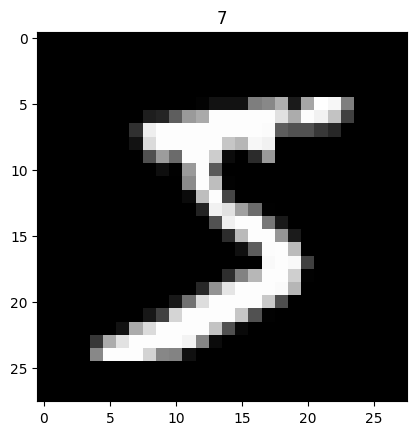

In [47]:
import matplotlib.pyplot as plt

plt.imshow(x_train[0] , cmap="gray")
plt.title(title_predictions[0])